# Access to Emergency Medical Services (Nathan Pozzuto)

The data within EMS.cvs lists the 20 EMS stations that service the neighborhoods of pittsburgh with their corresponding service districts. The 14 EMS districts in the City of Pittsburgh are geographic response territories assigned to specific Medic stations operated by the Pittsburgh Bureau of Emergency Medical Services. Each district ensures rapid Advanced Life Support (ALS) ambulance dispatch, pre-hospital medical care, and technical rescue coverage across all 90 city neighborhoods. My statistical analysis will compare the area that each station services (excluding district 13) to determine which neighborhood has the best access to emergency medical services.


![EMS districts](pittsburgh_ems_districts-2.png)

## Area
The area is important for determining the coverage by emergency medical services because a bigger area means that the station has to cover more physical space on average for each call. However, this is not the whole picture.

Note: Some districts are listed more than once because these are all graphs of the region that a single station covers and some distrcits have multiple stations.

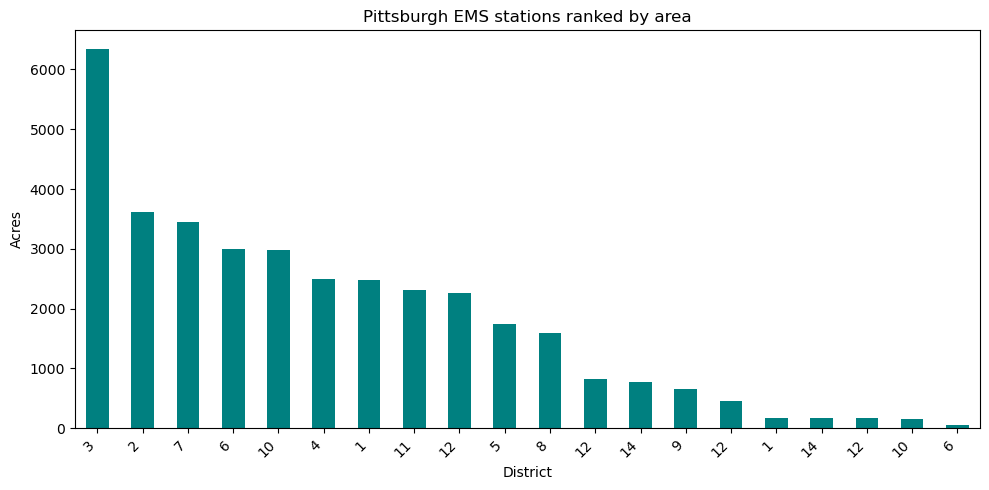

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("EMS.csv")
ranked = df.sort_values("acres", ascending=False)

ax = ranked.plot.bar(
    x="district",
    y="acres",
    legend=False,
    figsize=(10, 5),
    color="teal",
)
ax.set_title("Pittsburgh EMS stations ranked by area")
ax.set_xlabel("District")
ax.set_ylabel("Acres")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Perimeter
On top of area, perimeter is also important because it gives a better idea of the shape of the coverage zone. For example, a perfect circle would have the lowest perimeter for a given area so that is ideal for a equally distributed district. Having a much larger perimeter shows that the shape is more irregular.

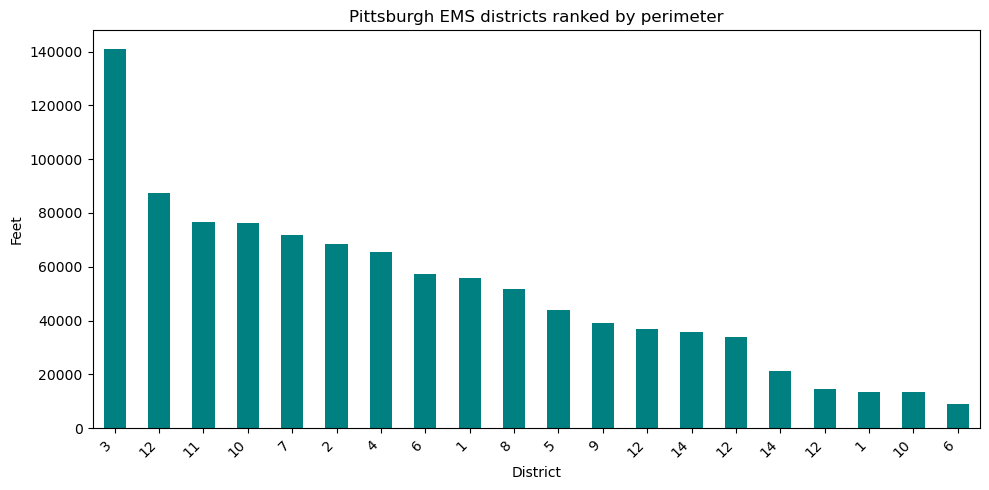

In [10]:
ranked = df.sort_values("perimeter", ascending=False)

ax = ranked.plot.bar(
    x="district",
    y="perimeter",
    legend=False,
    figsize=(10, 5),
    color="teal",
)
ax.set_title("Pittsburgh EMS districts ranked by perimeter")
ax.set_xlabel("District")
ax.set_ylabel("Feet")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Combined Metric
The code below combines the area column and perimeter column for each district to calculate a general coverage score including all stations in a district. This coverage score is essentially the "goodness percentage" and will be added to the group's final evaluation for each neighborhood.

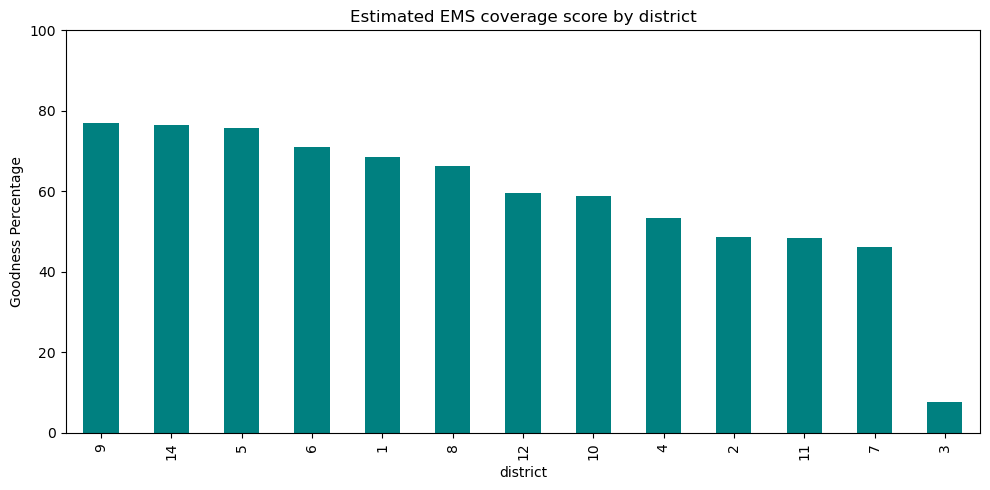

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

##both in feet
# One row per station, so combine rows into one row per district
def combine(g):
    n_stations = len(g)
    # If every station row repeats the same district area/perimeter, count it once.
    # If the values differ by row, they are separate pieces, so add them up.
    if g["area"].nunique() == 1:
        area = g["area"].iloc[0]
        perimeter = g["perimeter"].iloc[0]
    else:
        area = g["area"].sum()
        perimeter = g["perimeter"].sum()
    return pd.Series({"area": area, "perimeter": perimeter, "stations": n_stations})

districts = df.groupby("district").apply(combine, include_groups=False).reset_index()

area = districts["area"]
perimeter = districts["perimeter"]
stations = districts["stations"]

def scale(s, higher_is_better=True):
    rng = s.max() - s.min()
    s = (s - s.min()) / rng if rng != 0 else s * 0 + 0.5   # avoid dividing by zero
    return (s if higher_is_better else 1 - s) * 100

# Distance part: average distance from the nearest station.
# Each station is assumed to cover an equal share of the district's area.
area_per_station = area / stations
avg_dist = (2 / 3) * np.sqrt(area_per_station / np.pi)
distance_score = scale(avg_dist, higher_is_better=False)

# Shape part: compactness of the whole district, 1.0 = perfect circle
compactness = 4 * np.pi * area / perimeter**2
shape_score = scale(compactness, higher_is_better=True)

districts["coverage_score"] = (0.7 * distance_score + 0.3 * shape_score).round(1)

ranked = districts.sort_values("coverage_score", ascending=False)
##print(ranked[["district", "coverage_score"]])

ax = ranked.plot.bar(x="district", y="coverage_score", legend=False,
                     figsize=(10, 5), color="teal")
ax.set_ylim(0, 100)
ax.set_ylabel("Goodness Percentage")
ax.set_title("Estimated EMS coverage score by district")
plt.tight_layout()
plt.show()

In [19]:
import numpy as np

all_neighborhoods = [
    "Allegheny Center", "Allegheny West", "Allentown", "Arlington", "Arlington Heights",
    "Banksville", "Bedford Dwellings", "Beechview", "Beltzhoover", "Bloomfield", "Bluff",
    "Bon Air", "Brighton Heights", "Brookline", "California-Kirkbride", "Carrick",
    "Central Business District", "Central Lawrenceville", "Central North Side",
    "Central Oakland", "Chartiers City", "Chateau", "Crafton Heights", "Crawford-Roberts",
    "Duquesne Heights", "East Allegheny", "East Carnegie", "East Hills", "East Liberty",
    "Elliott", "Esplen", "Fairywood", "Fineview", "Friendship", "Garfield", "Glen Hazel",
    "Greenfield", "Hays", "Hazelwood", "Highland Park", "Homewood North", "Homewood South",
    "Homewood West", "Knoxville", "Larimer", "Lincoln Place", "Lincoln-Lemington-Belmar",
    "Lower Lawrenceville", "Manchester", "Marshall-Shadeland", "Middle Hill", "Morningside",
    "Mt. Oliver", "Mt. Washington", "New Homestead", "North Oakland", "North Shore",
    "Northview Heights", "Oakwood", "Overbrook", "Perry North", "Perry South", "Point Breeze",
    "Point Breeze North", "Polish Hill", "Regent Square", "Ridgemont", "Shadyside", "Sheraden",
    "South Oakland", "South Shore", "South Side Flats", "South Side Slopes", "Spring Garden",
    "Spring Hill-City View", "Squirrel Hill North", "Squirrel Hill South", "St. Clair",
    "Stanton Heights", "Strip District", "Summer Hill", "Swisshelm Park", "Terrace Village",
    "Troy Hill", "Upper Hill", "Upper Lawrenceville", "West End", "West Oakland", "Westwood",
    "Windgap",
]

district_neighborhoods = {
    "1":  ["Homewood North", "Homewood South", "Homewood West", "Lincoln-Lemington-Belmar",
           "Larimer", "East Liberty", "Highland Park"],
    "2":  ["Knoxville", "Bon Air", "Allentown", "Mt. Oliver", "Carrick", "Brookline", "Overbrook"],
    "3":  ["West End", "Beechview", "Banksville", "Mt. Washington", "Oakwood", "Westwood",
           "East Carnegie", "Elliott", "Sheraden", "Chartiers City"],
    "4":  ["Allegheny Center", "Allegheny West", "Central North Side", "Northview Heights",
           "Fineview", "Spring Hill-City View", "Perry South"],
    "5":  ["Crawford-Roberts", "Middle Hill", "Upper Hill", "South Oakland", "Central Oakland",
           "Polish Hill"],
    "6":  ["Garfield", "Central Lawrenceville", "Lower Lawrenceville", "Upper Lawrenceville",
           "Bloomfield", "Highland Park", "Stanton Heights", "Morningside"],
    "7":  ["Greenfield", "Squirrel Hill South", "Hazelwood", "Swisshelm Park"],
    "8":  ["Beltzhoover", "Mt. Washington", "South Side Flats", "South Side Slopes",
           "Arlington", "Arlington Heights"],
    "9":  ["Shadyside", "North Oakland", "Bloomfield", "East Liberty"],
    "10": ["Marshall-Shadeland", "Manchester", "Brighton Heights", "Perry North", "Summer Hill"],
    "12": ["Hays", "Lincoln Place", "St. Clair", "Hazelwood", "Glen Hazel", "New Homestead"],
    "14": ["Central Business District", "Bluff"],
}

# assumed districts for neighborhoods not located in the district
assumed = {
    "Bedford Dwellings": "5", "Terrace Village": "5", "West Oakland": "5",
    "California-Kirkbride": "4", "East Allegheny": "4", "North Shore": "4",
    "Spring Garden": "4", "Troy Hill": "4",
    "Chateau": "10",
    "Crafton Heights": "3", "Esplen": "3", "Fairywood": "3", "Ridgemont": "3", "Windgap": "3",
    "Duquesne Heights": "8", "South Shore": "8",
    "East Hills": "1", "Point Breeze North": "1",
    "Friendship": "9",
    "Point Breeze": "7", "Regent Square": "7", "Squirrel Hill North": "7",
    "Strip District": "6",
}

# Table of info per neighborhood
membership = {}   # neighborhood -> list of district keys
for k, names in district_neighborhoods.items():
    for n in names:
        membership.setdefault(n, []).append(k)

rows = []
for n in all_neighborhoods:
    if n in membership:
        ds, source = membership[n], "EMS list"
    elif n in assumed:
        ds, source = [assumed[n]], "assumed"
    else:
        ds, source = [], "missing"
    scores = [district_score[k] for k in ds if k in district_score.index]
    rows.append({"neighborhood": n,
                 "districts": ", ".join(ds),
                 "source": source,
                 "score": round(float(np.mean(scores)), 1) if scores else np.nan})

neighborhood_df = (pd.DataFrame(rows)
                   .sort_values("score", ascending=False)
                   .reset_index(drop=True))
neighborhood_scores = dict(zip(neighborhood_df["neighborhood"], neighborhood_df["score"]))

print(len(neighborhood_df), "neighborhoods,", neighborhood_df["score"].isna().sum(), "without a score")
print(neighborhood_df.to_string())

90 neighborhoods, 0 without a score
                 neighborhood districts    source  score
0               North Oakland         9  EMS list   77.0
1                  Friendship         9   assumed   77.0
2                   Shadyside         9  EMS list   77.0
3   Central Business District        14  EMS list   76.4
4                       Bluff        14  EMS list   76.4
5             Central Oakland         5  EMS list   75.7
6                 Middle Hill         5  EMS list   75.7
7            Crawford-Roberts         5  EMS list   75.7
8           Bedford Dwellings         5   assumed   75.7
9                  Upper Hill         5  EMS list   75.7
10               West Oakland         5   assumed   75.7
11                Polish Hill         5  EMS list   75.7
12              South Oakland         5  EMS list   75.7
13            Terrace Village         5   assumed   75.7
14                 Bloomfield      6, 9  EMS list   74.0
15               East Liberty      1, 9  EMS list   

## EMS Conclusion

Overall, when EMS access is quantified by compactness and shape as functions of area and perimeter, districts 9, 14, 5 score the best. After also accounting for neighborhoods not listed and neighborhoods listed twice, the table above scores each neighborhood. The neighborhoods with the best access to emergency medical services according to these calculations are North Oakland, Friendship, and Shadyside. The worst were all tied because they are in the same district. The limitation of this metric is that there are other factors involved in EMS access like number of ambulances, the call volume, and the actual travel time based on roads. That being said, this data set gives a decent idea of how close you are to an EMS station.
